In [114]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

In [115]:
exp_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/eps vs accuracy.csv')
FIL_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/FIL vs accuracy.csv')

In [116]:
xcol_exp = 'Validation accuracy'
xcol_FIL='final_accuracy'
ycol_exp='Exposure'
ycol_FIL='Final FIL'
name_exp_FIL='Name'

In [117]:
def clean_label(label):
    match = re.search(r'Num=\d+.*?(?:epsilon=\d+|No DP)', label)
    if match:
        clean = match.group(0).replace('Num=', 'n=').replace('epsilon', r'$\epsilon$')
        return clean
    else:
        return label.replace('Num=', 'n=')

In [ ]:
import matplotlib.colors as mcolors

base_colors = {
    'No DP': 'dimgray',
    r'$\epsilon$=32': 'darkred',
    r'$\epsilon$=8': 'darkblue',
    r'$\epsilon$=2': 'darkgreen',
}

intensity_map = {
    'n=16,': 1.0, 
    'n=4,': 0.7,
    'n=1,': 0.4,
}


def get_color(label):
    matched_color = None
    matched_intensity = None

    for dp_key in base_colors:
        if dp_key in label:
            matched_color = mcolors.to_rgb(base_colors[dp_key])
            break

    for n_key in intensity_map:
        if n_key in label:
            matched_intensity = intensity_map[n_key]
            break

    if matched_color and matched_intensity is not None:
        # Blend from white (for lightest) to base color (for darkest)
        white = (1.0, 1.0, 1.0)
        return tuple(
            (1 - matched_intensity) * w + matched_intensity * c
            for c, w in zip(matched_color, white)
        )
    else:
        return 'black'


In [ ]:
marker_map = {
    ('n=1,', r'$\epsilon$=2'): 'o',     # circle
    ('n=1,', r'$\epsilon$=8'): 's',     # square
    ('n=1,', r'$\epsilon$=32'): '^',    # triangle_up
    ('n=4,', r'$\epsilon$=2'): 'D',     # diamond
    ('n=4,', r'$\epsilon$=8'): 'v',     # triangle_down
    ('n=4,', r'$\epsilon$=32'): '<',    # triangle_left
    ('n=16,', r'$\epsilon$=2'): '>',    # triangle_right
    ('n=16,', r'$\epsilon$=8'): 'P',    # plus filled
    ('n=16,', r'$\epsilon$=32'): 'X',   # X filled
    ('n=1,', 'No DP'): '*',             # star
    ('n=4,', 'No DP'): 'h',             # hexagon
    ('n=16,', 'No DP'): 'H',            # rotated hexagon
}


def get_marker(label):
    for (n_key, eps_key), marker in marker_map.items():
        if n_key in label and eps_key in label:
            return marker
    return 'x'  

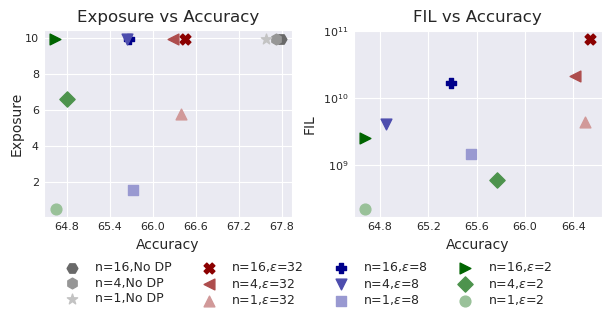

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(6, 2.5), constrained_layout=True)

all_handles = []
all_labels = []

# Left plot: Exposure vs Validation Accuracy
for i in range(len(exp_df)):
    x = exp_df.loc[i, xcol_exp]
    y = exp_df.loc[i, ycol_exp]
    label = clean_label(exp_df.loc[i, name_exp_FIL])
    color = get_color(label)
    pt = axs[0].scatter(x, y, label=label, s=60,marker=get_marker(label), color=color)
    all_handles.append(pt)
    all_labels.append(label)

axs[0].set_xlabel('Accuracy', fontsize=10)
axs[0].set_ylabel('Exposure', fontsize=10)
axs[0].tick_params(labelsize=8, pad=0)
axs[0].set_title('Exposure vs Accuracy', fontsize=12)
axs[0].yaxis.set_label_coords(-0.08, 0.5)
axs[0].xaxis.set_major_locator(plt.MaxNLocator(nbins=6))

# Right plot: FIL vs Final Accuracy
for i in range(len(FIL_df)):
    x = FIL_df.loc[i, xcol_FIL]
    y = FIL_df.loc[i, ycol_FIL]
    label = clean_label(FIL_df.loc[i, name_exp_FIL])
    color = get_color(label)
    pt = axs[1].scatter(x, y, label=label, s=60,marker=get_marker(label), color=color)
    if label not in all_labels:
        all_handles.append(pt)
        all_labels.append(label)
axs[1].set_yscale('log')
axs[1].set_xlabel('Accuracy', fontsize=10)
axs[1].set_ylabel('FIL', fontsize=10)
axs[1].set_title('FIL vs Accuracy', fontsize=12)
axs[1].tick_params(labelsize=8, pad=0)
axs[1].yaxis.set_label_coords(-0.15, 0.5)
axs[1].xaxis.set_major_locator(plt.MaxNLocator(nbins=6))

fig.legend(all_handles, all_labels, loc='lower center', ncol=4,
           bbox_to_anchor=(0.5, -0.25), labelspacing=0.2, frameon=False, fontsize=9)

plt.savefig("pdfs_save/exposure_fil_scatter.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

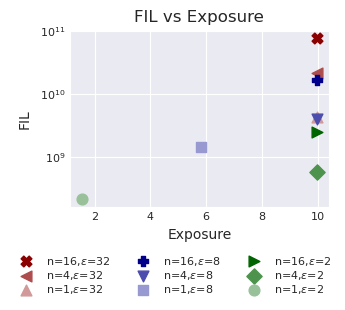

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(3.2, 2.4), constrained_layout=True)

all_handles = []
all_labels = []

# FIL vs Exposure
for i in range(len(FIL_df)):
    x = exp_df.loc[i, ycol_exp]      # Exposure on x-axis
    y = FIL_df.loc[i, ycol_FIL]      # FIL on y-axis
    label = clean_label(FIL_df.loc[i, name_exp_FIL])
    color = get_color(label)
    pt = ax.scatter(x, y, label=label, s=60,marker=get_marker(label), color=color)
    all_handles.append(pt)
    all_labels.append(label)

ax.set_xlabel('Exposure', fontsize=10)
ax.set_ylabel('FIL', fontsize=10, labelpad=10)
ax.set_yscale('log')
ax.set_title('FIL vs Exposure', fontsize=12)
ax.tick_params(labelsize=8, pad=0)
ax.yaxis.set_label_coords(-0.15, 0.5)

fig.legend(all_handles, all_labels, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.25), labelspacing=0.1, frameon=False, fontsize=8)

plt.savefig("pdfs_save/fil_vs_exposure.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()